---
title: "Scattering — Level 2"
short_title: "11 Scattering"
numbering:
  heading_2: true
  equation: true
---

# Scattering

:::{seealso} Math for this topic
- [Q-M5: Asymptotics, WKB and Bessel functions](../math/05-asymptotics-wkb-bessel.ipynb)
- [E-M2: Separation of variables and orthogonal functions](../../level2-em-book/math/02-separation-of-variables.ipynb)
- [E-M3: Waves and Fourier transforms](../../level2-em-book/math/03-waves-fourier-transforms.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered; start at Level 2 |
| **2** | **Griffiths QM, ch. 11** | **Partial waves, phase shifts, the Born approximation** |
| 3 | Sakurai, ch. 6 | The Lippmann–Schwinger equation, the optical theorem, resonances |

The new skill at this level: describing a collision by the angular pattern of an outgoing spherical wave, computed either wave by wave or in a weak-potential approximation

Math for this topic: Q-M5 (spherical Bessel functions, Rayleigh's formula), E&M E-M2 (Legendre polynomials) and E&M E-M3 (Fourier transforms).
:::

Workbook example ladder: the Born cross section for a Yukawa potential → partial-wave phase shifts → the optical theorem and resonances. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Cross Sections

Most of what is known about forces between particles comes from scattering: send a beam at a target and count what comes out in each direction. The **differential cross section** $d\sigma/d\Omega$ is defined so that the number scattered per second into solid angle $d\Omega$ is $\mathcal L\,d\sigma$, where $\mathcal L$ is the incident flux (particles per area per second). It has units of area: the effective target area that sends particles into that direction. The **total cross section** is $\sigma = \int\frac{d\sigma}{d\Omega}d\Omega$.

Classically, a hard sphere of radius $a$ has $\sigma = \pi a^2$, its shadow. Rutherford scattering from a Coulomb potential has $d\sigma/d\Omega\propto1/\sin^4(\theta/2)$ and infinite total cross section (the force has infinite range).

## The Quantum Setup

Far from a target with a short-range potential, the wave function of a scattering state at energy $E = \hbar^2k^2/2m$ is an incoming plane wave plus an outgoing spherical wave:

$$
\psi(\vec r)\approx A\left[e^{ikz} + f(\theta)\frac{e^{ikr}}{r}\right],\qquad r\to\infty .
$$ (eq-scattering-asymptotic)

The **scattering amplitude** $f(\theta)$ carries all the information (for a spherically symmetric potential it does not depend on $\phi$), and comparing the probability currents of the two terms gives

$$
\frac{d\sigma}{d\Omega} = |f(\theta)|^2 .
$$ (eq-dsigma-f)

Two methods compute $f$: **partial waves** (exact in principle, best at low energy) and the **Born approximation** (approximate, best for weak potentials or high energy).

## Partial Waves

Expand everything in angular momentum. The incident plane wave is a sum of spherical waves (Rayleigh's formula, Q-M5), one for each $\ell$. Outside the potential, each partial wave is a free radial solution: a combination of $j_\ell(kr)$ and $n_\ell(kr)$. Far away, $j_\ell\to\sin(kr - \ell\pi/2)/kr$, and the potential's only effect is to shift the phase of each wave by an amount $\delta_\ell$, the **phase shift**:

$$
u_\ell(r)\propto\sin\!\left(kr - \frac{\ell\pi}{2} + \delta_\ell\right)\quad(r\to\infty) .
$$ (eq-phase-shift)

Matching to {eq}`eq-scattering-asymptotic` gives

$$
f(\theta) = \frac1k\sum_{\ell=0}^\infty(2\ell + 1)e^{i\delta_\ell}\sin\delta_\ell\,P_\ell(\cos\theta),\qquad
\sigma = \frac{4\pi}{k^2}\sum_{\ell=0}^\infty(2\ell + 1)\sin^2\delta_\ell .
$$ (eq-partial-wave-f)

Each partial wave contributes at most $4\pi(2\ell + 1)/k^2$ (when $\delta_\ell = \pi/2$, a resonance). Semiclassically, a particle with angular momentum $\ell\hbar = pb$ passes at impact parameter $b = \ell/k$, so a potential of range $a$ affects only $\ell\lesssim ka$. At low energy ($ka\ll1$) only the $s$ wave ($\ell = 0$) matters and the scattering is isotropic.

### The hard sphere

For $V = \infty$ at $r < a$, the wave must vanish at $r = a$: $\cos\delta_\ell\,j_\ell(ka) - \sin\delta_\ell\,n_\ell(ka) = 0$, so

$$
\tan\delta_\ell = \frac{j_\ell(ka)}{n_\ell(ka)} .
$$ (eq-hard-sphere-delta)

At low energy $\delta_0\approx-ka$ and $\sigma\to4\pi a^2$, **four times** the classical shadow: a slow wave diffracts around the whole surface. At high energy $\sigma\to2\pi a^2$, twice the shadow; the extra $\pi a^2$ is the forward diffraction peak that, together with the shadow, makes the hole in the beam behind the sphere.

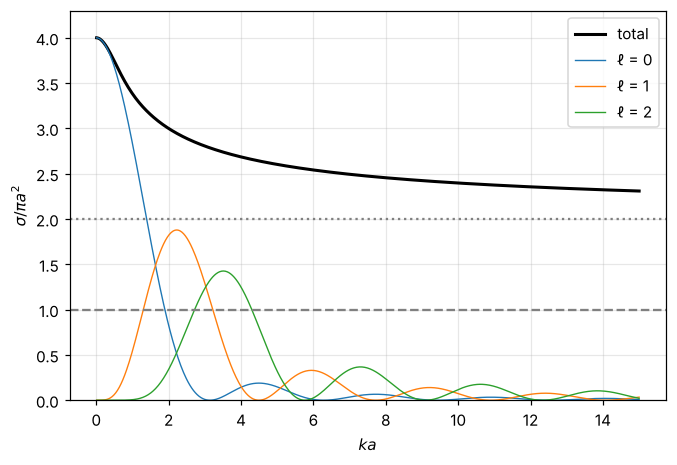

In [2]:
#| label: fig-hard-sphere
#| caption: "Total cross section of a hard sphere (in units of the classical πa²) versus ka, from the partial-wave sum with tan δ_ℓ = j_ℓ(ka)/n_ℓ(ka). It falls from 4 (low-energy s-wave scattering) toward 2 at high energy, never reaching the classical value 1 (dashed). Thin lines show the s, p and d contributions."
from scipy.special import spherical_jn, spherical_yn
ka = np.linspace(0.01, 15, 600)
def deltas(ka, lmax):
    return np.array([np.arctan2(spherical_jn(l, ka), spherical_yn(l, ka)) for l in range(lmax + 1)])
lmax = 40
dl = deltas(ka, lmax)
contrib = np.array([(2 * l + 1) * np.sin(dl[l])**2 for l in range(lmax + 1)]) * 4 / ka**2    # sigma/(pi a^2)
fig, ax = plt.subplots()
ax.plot(ka, contrib.sum(0), "k", lw=2, label="total")
for l, col in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(ka, contrib[l], color=col, lw=0.9, label=f"ℓ = {l}")
ax.axhline(1, ls="--", color="gray"); ax.axhline(2, ls=":", color="gray")
ax.set_ylim(0, 4.3); ax.set_xlabel("$ka$"); ax.set_ylabel("$\\sigma / \\pi a^2$"); ax.legend(); plt.show()

## The Born Approximation

Write the Schrödinger equation as $(\nabla^2 + k^2)\psi = \frac{2m}{\hbar^2}V\psi$ and solve it with the Green's function of the left side (the outgoing spherical wave $-e^{ik|\vec r - \vec r'|}/4\pi|\vec r - \vec r'|$). If $V$ is weak, replace $\psi$ on the right by the incident plane wave. The result:

$$
f_{\text{Born}}(\theta) = -\frac{m}{2\pi\hbar^2}\int e^{i\vec q\cdot\vec r'}V(\vec r')\,d^3r',\qquad\vec q = \vec k - \vec k',\quad q = 2k\sin\frac\theta2 .
$$ (eq-born)

**The scattering amplitude is the Fourier transform of the potential** at the momentum transfer $\hbar\vec q$ (E-M3). For a spherically symmetric potential the angular integral can be done:

$$
f_{\text{Born}}(\theta) = -\frac{2m}{\hbar^2q}\int_0^\infty rV(r)\sin(qr)\,dr .
$$ (eq-born-spherical)

Measuring $d\sigma/d\Omega$ at many angles maps out $\tilde V(q)$, and so the shape of the target. That is how electron scattering measured the size and charge distribution of nuclei and protons.

::::{prf:example} Level 2 rung: the Yukawa potential
:label: ex-yukawa-born

Find the Born cross section for $V(r) = \beta\,e^{-\mu r}/r$ (the potential of a force carried by a particle of mass $\hbar\mu/c$; Yukawa's model of the nuclear force).

:::{dropdown} Solution
$\int_0^\infty e^{-\mu r}\sin(qr)\,dr = q/(\mu^2 + q^2)$, so

$$
f_{\text{Born}} = -\frac{2m\beta}{\hbar^2(\mu^2 + q^2)},\qquad
\frac{d\sigma}{d\Omega} = \left(\frac{2m\beta}{\hbar^2}\right)^2\frac{1}{\left(\mu^2 + 4k^2\sin^2\frac\theta2\right)^2} .
$$

Letting $\mu\to0$ with $\beta = q_1q_2/4\pi\epsilon_0$ gives exactly the Rutherford formula, $d\sigma/d\Omega = \left(\frac{q_1q_2}{16\pi\epsilon_0E}\right)^2\frac{1}{\sin^4(\theta/2)}$, which happens to be exact for the Coulomb potential as well as being its Born approximation.
:::
::::

In [3]:
r, q, mu, beta, m, hb = sp.symbols("r q mu beta m hbar", positive=True)
f_born = sp.simplify(-2 * m / (hb**2 * q) * sp.integrate(r * beta * sp.exp(-mu * r) / r * sp.sin(q * r), (r, 0, sp.oo)))
display(Math(r"f_{\rm Born}(q) = " + sp.latex(f_born)))
th, k, E = sp.symbols("theta k E", positive=True)
ds = sp.simplify((f_born**2).subs(q, 2 * k * sp.sin(th / 2)))
ruth = sp.simplify(ds.subs(mu, 0).subs(k, sp.sqrt(2 * m * E) / hb))
display(Math(r"\frac{d\sigma}{d\Omega}\Big|_{\mu\to0} = " + sp.latex(ruth)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

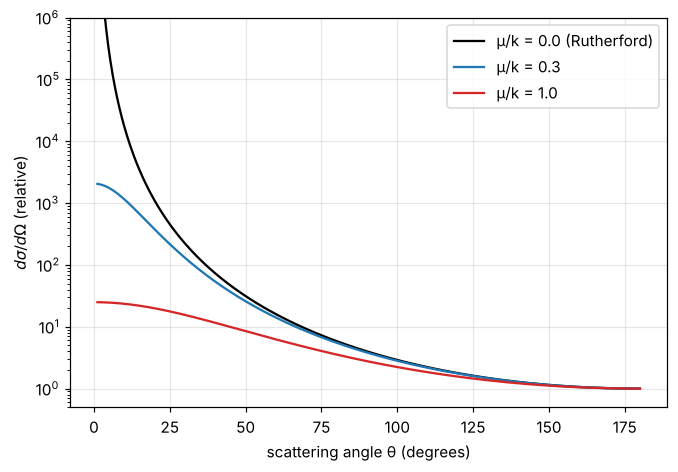

In [4]:
#| label: fig-yukawa
#| caption: "Born differential cross sections for the Yukawa potential at fixed k, for range parameters μ/k = 0 (Rutherford), 0.3 and 1 (normalized at 180°). A finite range removes the forward divergence; the shape at small angles reveals μ, the inverse range of the force."
thv = np.linspace(0.02, np.pi, 500)
fig, ax = plt.subplots()
for mu_k, col in [(0.0, "k"), (0.3, "tab:blue"), (1.0, "tab:red")]:
    dsv = 1 / (mu_k**2 + 4 * np.sin(thv / 2)**2)**2
    ax.semilogy(np.degrees(thv), dsv / dsv[-1], color=col, label=f"μ/k = {mu_k}" + (" (Rutherford)" if mu_k == 0 else ""))
ax.set_xlabel("scattering angle θ (degrees)"); ax.set_ylabel("$d\\sigma/d\\Omega$ (relative)"); ax.set_ylim(0.5, 1e6); ax.legend(); plt.show()

## Testing the Born Approximation

Born should work when the potential barely distorts the incident wave. A clean test: an attractive spherical well, $V = -V_0$ for $r < a$, whose phase shifts can be computed exactly by matching the inside solution ($j_\ell(\kappa r)$ with $\kappa^2 = k^2 + 2mV_0/\hbar^2$) to the outside one. In units where $\hbar^2/2m = 1$ and $a = 1$, the strength is measured by $V_0$ itself; the well binds its first state at $V_0 = \pi^2/4\approx2.47$.

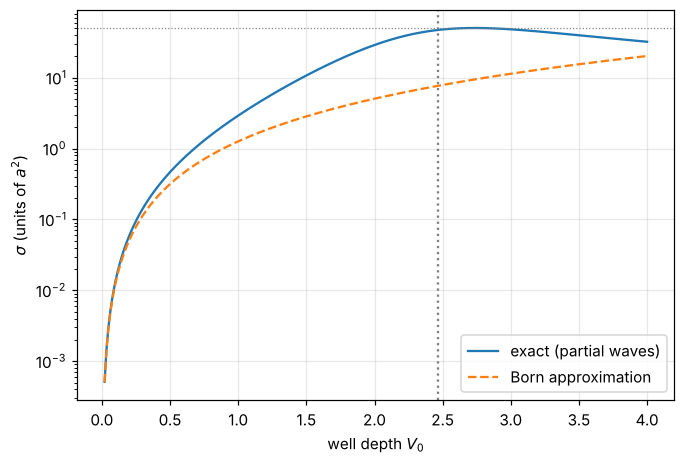

In [5]:
#| label: fig-born-test
#| caption: "Total cross section of an attractive spherical well (ħ²/2m = 1, a = 1) at ka = 0.5, versus well depth V₀: exact partial waves (solid) against the Born approximation (dashed). Born agrees for weak wells but misses the resonance near V₀ = π²/4 ≈ 2.47, where the well is about to bind a state and the s-wave cross section climbs to its maximum 4π/k² (dotted); there Born is low by a factor of about 5."
from scipy.special import spherical_jn, spherical_yn
def phase_shift(l, k, V0):
    K = np.sqrt(k**2 + V0)
    # match logarithmic derivative of j_l(K r) at r = 1 to cos(d) j_l(k r) - sin(d) n_l(k r)
    jl, jlp = spherical_jn(l, K), spherical_jn(l, K, derivative=True) * K
    g = jlp / jl
    num = k * spherical_jn(l, k, derivative=True) - g * spherical_jn(l, k)
    den = k * spherical_yn(l, k, derivative=True) - g * spherical_yn(l, k)
    return np.arctan(num / den)
def sigma_exact(k, V0, lmax=8):
    return 4 * np.pi / k**2 * sum((2 * l + 1) * np.sin(phase_shift(l, k, V0))**2 for l in range(lmax + 1))
def sigma_born(k, V0):
    th = np.linspace(0, np.pi, 2001); qq = 2 * k * np.sin(th / 2) + 1e-12
    f = (V0 / qq**2) * (np.sin(qq) - qq * np.cos(qq)) / qq          # -(2m/hbar^2 q) * integral r (-V0) sin(qr) dr, with 2m/hbar^2 = 1
    return 2 * np.pi * np.trapezoid(f**2 * np.sin(th), th)
k0 = 0.5
V0s = np.linspace(0.02, 4, 300)
fig, ax = plt.subplots()
ax.plot(V0s, [sigma_exact(k0, v) for v in V0s], label="exact (partial waves)")
ax.plot(V0s, [sigma_born(k0, v) for v in V0s], "--", label="Born approximation")
ax.axvline(np.pi**2 / 4, color="gray", ls=":"); ax.axhline(4 * np.pi / k0**2, color="gray", ls=":", lw=0.8)
ax.set_xlabel("well depth $V_0$"); ax.set_ylabel("$\\sigma$ (units of $a^2$)"); ax.set_yscale("log"); ax.legend(); plt.show()

## Looking Ahead to Level 3

Sakurai turns the Green's-function step into an exact integral equation, the **Lippmann–Schwinger equation** $|\psi\rangle = |\phi\rangle + \frac{1}{E - \hat H_0 + i\epsilon}\hat V|\psi\rangle$, whose iteration is the Born series. Conservation of probability gives the **optical theorem**, $\sigma = \frac{4\pi}{k}\operatorname{Im}f(0)$: the total cross section is fixed by the forward amplitude, because scattering out of the beam must show up as a shadow interfering with the forward wave. Near a **resonance**, a phase shift rises rapidly through $\pi/2$ and the cross section follows a Breit–Wigner peak, the scattering signature of a long-lived quasi-bound state.

## Exercises

### Exercises

1. Show that for $s$-wave scattering, $d\sigma/d\Omega = \sin^2\delta_0/k^2$, independent of angle.
2. Find $\delta_0$ for a hard sphere exactly, and show that $\sigma\to4\pi a^2$ as $k\to0$.
3. Find the Born amplitude for a Gaussian potential $V = V_0e^{-r^2/b^2}$, using the 3D Fourier transform.
4. Electrons of 500 MeV scatter from a nucleus. Estimate the smallest structure they can resolve. ($q_{\max} = 2k$.)
5. Use the optical theorem with the partial-wave $f(\theta)$ to rederive the expression for $\sigma$ in {eq}`eq-partial-wave-f`.

:::{dropdown} Hints
1. Only the $\ell = 0$ term, with $P_0 = 1$.
2. $j_0/n_0 = -\tan(ka)$.
3. $\int e^{i\vec q\cdot\vec r}e^{-r^2/b^2}d^3r = \pi^{3/2}b^3e^{-q^2b^2/4}$.
4. Resolution $\sim1/q_{\max}$ with $k = E/\hbar c$.
5. $\operatorname{Im}(e^{i\delta}\sin\delta) = \sin^2\delta$ and $P_\ell(1) = 1$.
:::

:::{dropdown} Answers
1. $f = e^{i\delta_0}\sin\delta_0/k$, so $|f|^2 = \sin^2\delta_0/k^2$.
2. $\delta_0 = -ka$ exactly; $\sigma_0 = 4\pi\sin^2(ka)/k^2\to4\pi a^2$.
3. $f = -\frac{m V_0b^3}{2\sqrt\pi\hbar^2}e^{-q^2b^2/4}$: forward-peaked, with angular width set by $1/kb$.
4. $k = 500/197.3\text{ fm}^{-1} = 2.5$ fm⁻¹, $q_{\max} = 5$ fm⁻¹: about 0.2 fm, finer than a nucleon.
5. $\frac{4\pi}{k}\cdot\frac1k\sum(2\ell + 1)\sin^2\delta_\ell$, matching {eq}`eq-partial-wave-f`.
:::

## Summary

- $d\sigma/d\Omega = |f(\theta)|^2$, where $f$ is the amplitude of the outgoing spherical wave.
- Partial waves: each $\ell$ is shifted by $\delta_\ell$; $\sigma = \frac{4\pi}{k^2}\sum(2\ell + 1)\sin^2\delta_\ell$, dominated by $\ell\lesssim ka$. A hard sphere gives $4\pi a^2$ at low energy and $2\pi a^2$ at high energy.
- Born: $f$ is $-\frac{m}{2\pi\hbar^2}$ times the Fourier transform of $V$ at $\vec q$; Yukawa reduces to Rutherford as the range goes to infinity.
- Born works for weak potentials and fails near resonances, where partial waves are needed.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.